# Análisis Exploratorio de Datos — Barras

Este notebook realiza un EDA independiente del catálogo **dataset.csv**, disponible para el módulo futuro de detección de barras galácticas.

**Alcance:** describe la estructura del catálogo, la variable de barras, calidad de datos, relaciones entre coordenadas/redshift y las decisiones de preprocesamiento. No entrena un modelo ni presupone imágenes FITS disponibles.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titleweight'] = 'bold'

CANDIDATE_PATHS = [
    Path('dataset.csv'),
    Path('data_download/dataset.csv'),
    Path('../data_download/dataset.csv'),
]
PATH_DATASET = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if PATH_DATASET is None:
    raise FileNotFoundError('No se encontró dataset.csv. Colócalo junto al notebook o en data_download/catalogs/.')

print(f'CSV utilizado: {PATH_DATASET.resolve()}')

CSV utilizado: C:\Users\VACORTES\Documents\GalMorphAI\BarGalaxiesAnalysis\data_download\dataset.csv


## Estructura de los datos

### Diccionario de variables

| Variable | Tipo esperado | Descripción |
|---|---|---|
| name | texto | Identificador MaNGA de la galaxia. |
| objra | numérica | Ascensión recta (RA) en grados. |
| objdec | numérica | Declinación (Dec) en grados. |
| Bars | categórica codificada | Código morfológico de barras disponible en el catálogo. Se analiza como categoría, no como escala continua. |
| z | numérica | Redshift de la galaxia. El valor -9999 representa dato no disponible. |

In [2]:
df_raw = pd.read_csv(PATH_DATASET)
print(f'dataset.csv: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas')
display(df_raw.head())

dataset.csv: 10,126 filas × 5 columnas


,name,objra,objdec,Bars,z
0,manga-10001-12701,133.371091,57.598425,0.0,0.039207
1,manga-10001-12702,133.685670,57.480250,0.5,0.040811
2,manga-10001-12703,136.017160,57.092329,0.5,0.046209
3,manga-10001-12704,133.989967,57.677968,0.0,0.014122
4,manga-10001-12705,136.751375,57.451437,0.0,0.046235


In [3]:
print('--- Tipos de datos ---')
print(df_raw.dtypes)

print('\n--- Estadísticas descriptivas originales ---')
display(df_raw.describe(include='all').T)

--- Tipos de datos ---
name          str
objra     float64
objdec    float64
Bars      float64
z         float64
dtype: object

--- Estadísticas descriptivas originales ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,10126,10126,manga-10001-12701,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
objra,10126.0,NaN,NaN,NaN,183.138344,76.30184,0.008808,128.891916,194.107467,239.689169,359.858576
objdec,10126.0,NaN,NaN,NaN,28.62491,17.968381,-9.302426,14.652696,29.368107,43.866542,65.289735
Bars,10126.0,NaN,NaN,NaN,0.248914,0.37319,-0.5,0.0,0.0,0.5,1.0
z,10125.0,NaN,NaN,NaN,-26.618146,515.685057,-9999.0,0.025918,0.03754,0.055555,0.149719


In [4]:
print('--- Frecuencia de códigos Bars ---')
counts_bars = df_raw['Bars'].value_counts(dropna=False).sort_index()
display(counts_bars.rename('frecuencia').to_frame())

print('--- Valores faltantes originales ---')
missing = pd.DataFrame({
    'missing': df_raw.isna().sum(),
    'pct': (100 * df_raw.isna().sum() / len(df_raw)).round(3)
})
display(missing)

--- Frecuencia de códigos Bars ---


,frecuencia
Bars,
-0.50,93
0.00,6254
0.25,436
0.50,1542
0.75,456
1.00,1345


--- Valores faltantes originales ---


,missing,pct
name,0,0.00
objra,0,0.00
objdec,0,0.00
Bars,0,0.00
z,1,0.01


In [5]:
print('Duplicados exactos:                ', df_raw.duplicated().sum())
print('Duplicados por name:                ', df_raw.duplicated(subset='name').sum())
print('Cardinalidad name (únicos / total): ', f"{df_raw['name'].nunique()} / {len(df_raw)}")
print('Cardinalidad Bars:                  ', df_raw['Bars'].nunique())
print('Valores centinela z = -9999:        ', (df_raw['z'] == -9999).sum())

Duplicados exactos:                 0
Duplicados por name:                 0
Cardinalidad name (únicos / total):  10126 / 10126
Cardinalidad Bars:                   6
Valores centinela z = -9999:         27


> **Mejora que el equipo está actualizando — 30 de septiembre de 2026.**
> **Patrones de ausencia en redshift:** Además de limpiar los valores -9999, se cuantifica si los redshifts no disponibles se concentran en algún código Bars.

In [6]:
df = df_raw.copy()
df['z'] = df['z'].replace(-9999, np.nan)

print('Valores no disponibles en z después de limpiar:', df['z'].isna().sum())
print('Registros válidos para análisis de redshift:    ', df['z'].notna().sum())

Valores no disponibles en z después de limpiar: 28
Registros válidos para análisis de redshift:     10098


In [7]:
df_missing_pattern = (
    df.assign(z_missing=df['z'].isna())
      .groupby('Bars')['z_missing']
      .agg(faltantes='sum', total='count', porcentaje=lambda x: 100 * x.mean())
      .round(3)
)
print('--- Patrón de ausencia de redshift por código Bars ---')
display(df_missing_pattern)

--- Patrón de ausencia de redshift por código Bars ---


,faltantes,total,porcentaje
Bars,,,
-0.50,0,93,0.000
0.00,27,6254,0.432
0.25,1,436,0.229
0.50,0,1542,0.000
0.75,0,456,0.000
1.00,0,1345,0.000


**Hallazgos de estructura**

- **name** es un identificador de alta cardinalidad y no debe utilizarse como variable predictora.
- **Bars** es la etiqueta/código morfológico y debe tratarse como categórica.
- **z** requiere limpieza porque contiene un valor nulo y valores centinela -9999.
- No se eliminan galaxias por redshift faltante: la decisión de imputar o excluir z dependerá de si se usa como metadato en una etapa posterior.

## Análisis univariante

Las variables continuas se visualizan con histogramas y boxplots; el código de barras se visualiza con frecuencias.

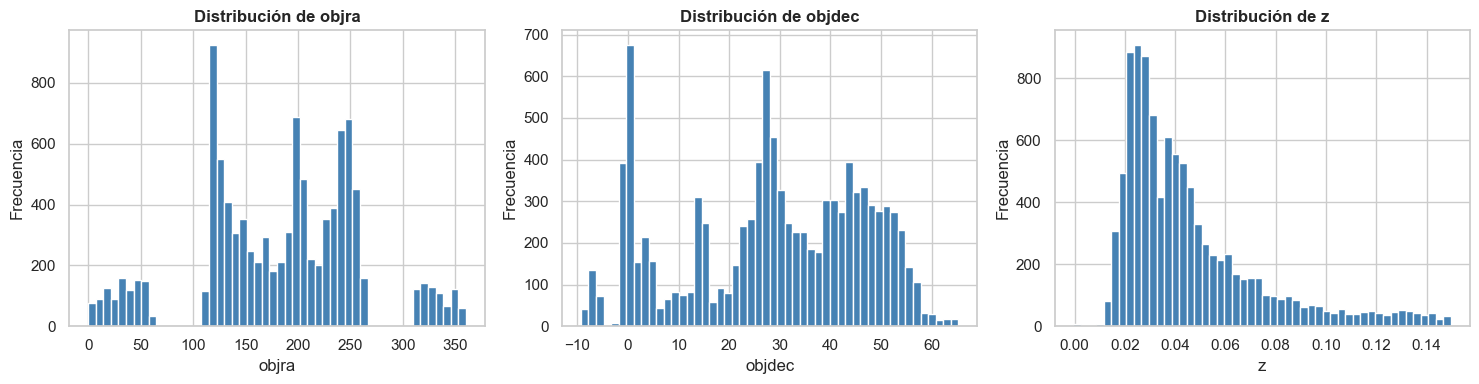

In [8]:
num_cols = ['objra', 'objdec', 'z']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    values = df[col].dropna()
    ax.hist(values, bins=50, color='steelblue', edgecolor='white')
    ax.set_title(f'Distribución de {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

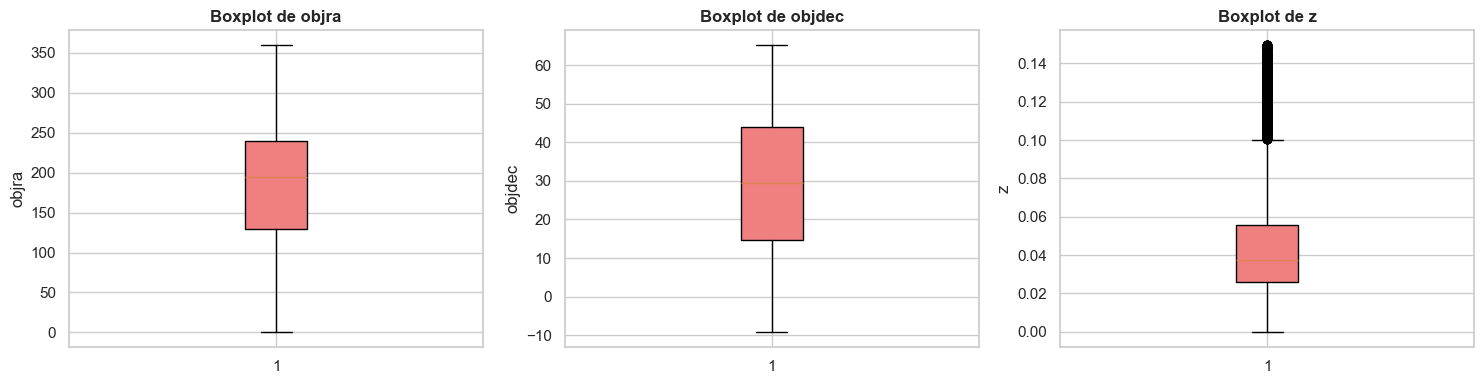

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    ax.boxplot(df[col].dropna(), vert=True, patch_artist=True, boxprops=dict(facecolor='lightcoral'))
    ax.set_title(f'Boxplot de {col}')
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

In [10]:
summary_num = pd.DataFrame({
    'media': df[num_cols].mean(),
    'mediana': df[num_cols].median(),
    'std': df[num_cols].std(),
    'skewness': df[num_cols].apply(lambda x: stats.skew(x.dropna())),
    'kurtosis': df[num_cols].apply(lambda x: stats.kurtosis(x.dropna())),
})
print('--- Resumen de variables numéricas limpias ---')
display(summary_num.round(4))

--- Resumen de variables numéricas limpias ---


,media,mediana,std,skewness,kurtosis
objra,183.1383,194.1075,76.3018,-0.1666,-0.0845
objdec,28.6249,29.3681,17.9684,-0.3165,-0.9638
z,0.0460,0.0376,0.0284,1.5807,2.1668


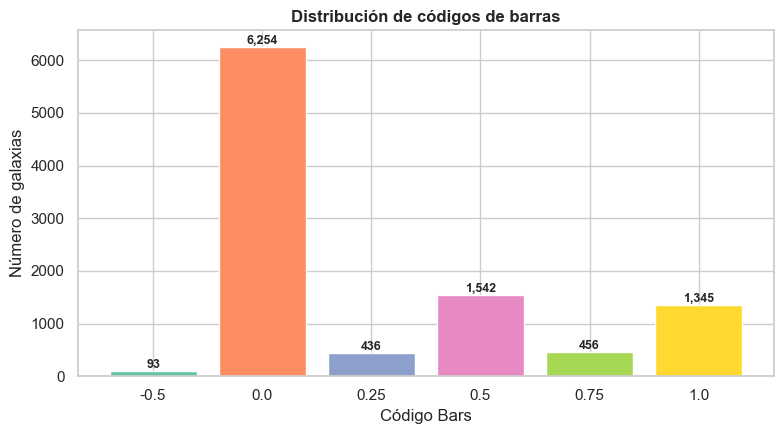

,frecuencia,porcentaje
Bars,,
-0.50,93,0.92
0.00,6254,61.76
0.25,436,4.31
0.50,1542,15.23
0.75,456,4.50
1.00,1345,13.28


In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
counts_bars = df['Bars'].value_counts().sort_index()
colors = sns.color_palette('Set2', len(counts_bars))
ax.bar(counts_bars.index.astype(str), counts_bars.values, color=colors)
ax.set_title('Distribución de códigos de barras')
ax.set_xlabel('Código Bars')
ax.set_ylabel('Número de galaxias')
for i, value in enumerate(counts_bars.values):
    ax.text(i, value + counts_bars.max() * 0.01, f'{value:,}', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

bar_pct = (100 * counts_bars / len(df)).round(2)
display(pd.DataFrame({'frecuencia': counts_bars, 'porcentaje': bar_pct}))

## Análisis bi/multivariante

Se analizan correlaciones entre variables continuas. Dado que **Bars** es una categoría codificada, no se interpreta una correlación lineal con ese campo; en su lugar se comparan distribuciones de redshift y cobertura espacial por categoría.

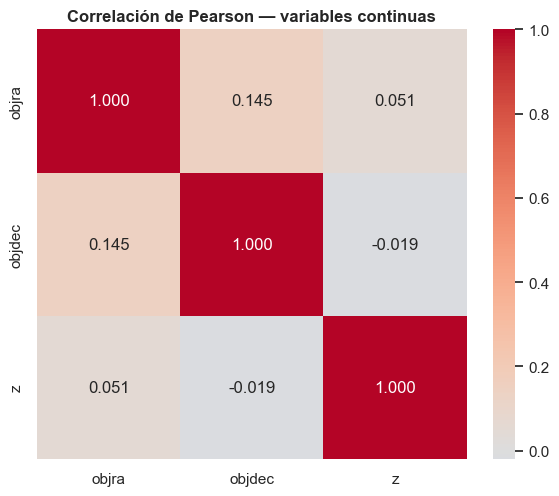

--- Matriz de correlación ---
        objra  objdec      z
objra   1.000   0.145  0.051
objdec  0.145   1.000 -0.019
z       0.051  -0.019  1.000


In [12]:
corr = df[['objra', 'objdec', 'z']].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.3f', square=True, ax=ax)
ax.set_title('Correlación de Pearson — variables continuas')
plt.tight_layout()
plt.show()

print('--- Matriz de correlación ---')
print(corr.round(3).to_string())

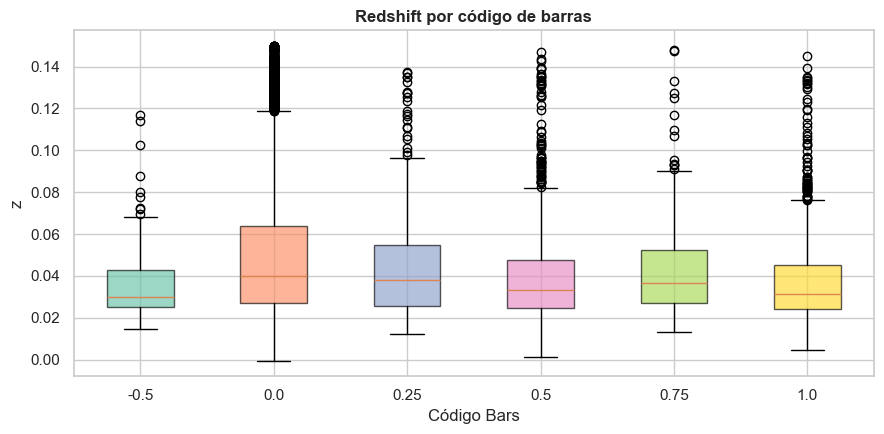

Kruskal-Wallis: H=268.36, p-value=6.29e-56


,count,median,mean,std
Bars,,,,
-0.50,93,0.0300,0.0371,0.0209
0.00,6227,0.0400,0.0501,0.0315
0.25,435,0.0382,0.0442,0.0248
0.50,1542,0.0335,0.0391,0.0206
0.75,456,0.0366,0.0422,0.0205
1.00,1345,0.0314,0.0372,0.0195


In [13]:
order_bars = sorted(df['Bars'].dropna().unique())
box_data = [df.loc[df['Bars'] == code, 'z'].dropna() for code in order_bars]

fig, ax = plt.subplots(figsize=(9, 4.5))
bp = ax.boxplot(box_data, labels=[str(x) for x in order_bars], patch_artist=True)
for patch, color in zip(bp['boxes'], sns.color_palette('Set2', len(box_data))):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)
ax.set_title('Redshift por código de barras')
ax.set_xlabel('Código Bars')
ax.set_ylabel('z')
plt.tight_layout()
plt.show()

valid_groups = [values for values in box_data if len(values) > 1]
if len(valid_groups) > 1:
    statistic, pvalue = stats.kruskal(*valid_groups)
    print(f'Kruskal-Wallis: H={statistic:.2f}, p-value={pvalue:.2e}')
    display(df.groupby('Bars')['z'].agg(['count', 'median', 'mean', 'std']).round(4))

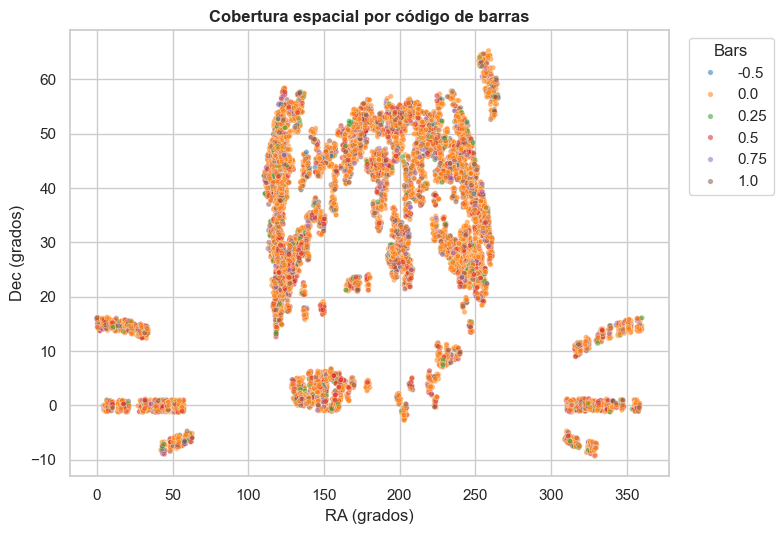

In [14]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=df, x='objra', y='objdec', hue='Bars', palette='tab10', alpha=0.55, s=15, ax=ax)
ax.set_title('Cobertura espacial por código de barras')
ax.set_xlabel('RA (grados)')
ax.set_ylabel('Dec (grados)')
ax.legend(title='Bars', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

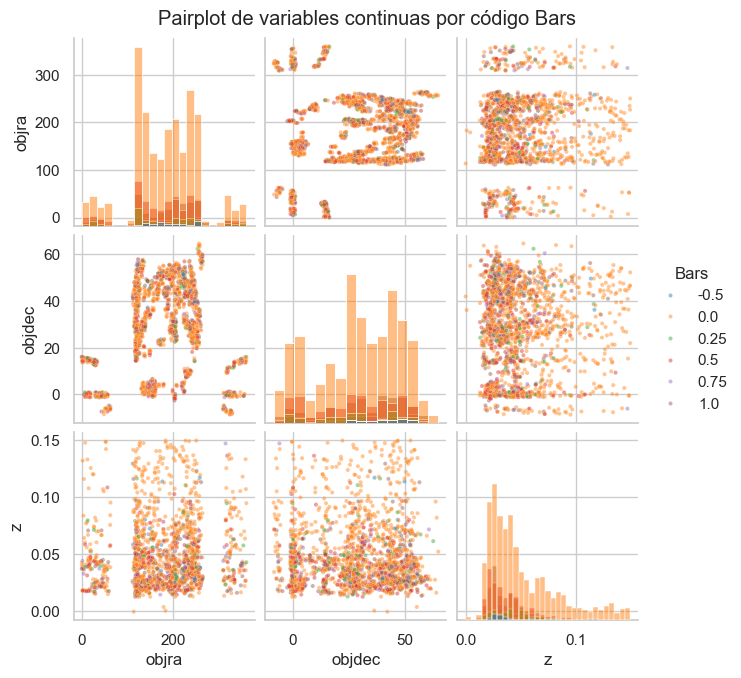

In [15]:
sample = df[['objra', 'objdec', 'z', 'Bars']].dropna().sample(min(2000, df['z'].notna().sum()), random_state=42)
g = sns.pairplot(sample, hue='Bars', palette='tab10', plot_kws={'s': 9, 'alpha': 0.45}, diag_kind='hist', height=2.2)
g.fig.suptitle('Pairplot de variables continuas por código Bars', y=1.02)
plt.show()

> **Mejora que el equipo está actualizando — 30 de septiembre de 2026.**
> **Cuantificación de valores atípicos:** Se calcula el criterio IQR sobre redshift limpio para documentar cuántas observaciones están en la cola, sin eliminarlas automáticamente.

In [16]:
z_valid = df['z'].dropna()
q1, q3 = z_valid.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_mask = (z_valid < lo) | (z_valid > hi)

print(f'IQR de z: [{lo:.4f}, {hi:.4f}]')
print(f'Atípicos por IQR: {outlier_mask.sum()} ({100 * outlier_mask.mean():.2f} %)')
print(f'Skewness original: {stats.skew(z_valid):.4f}')
print(f'Skewness log(1+z): {stats.skew(np.log1p(z_valid)):.4f}')

IQR de z: [-0.0185, 0.1002]
Atípicos por IQR: 688 (6.81 %)
Skewness original: 1.5807
Skewness log(1+z): 1.5151


## Preprocesamiento

| Operación | Decisión | Justificación |
|---|---|---|
| Valores faltantes y centinela en z | Convertir -9999 a NaN; crear indicador de ausencia e imputar mediana solo si z se usa como metadato | Evita interpretar un código de ausencia como distancia real y conserva las galaxias. |
| Atípicos en z | Conservar observaciones y crear log(1+z) | Los redshifts extremos pueden ser válidos; la transformación reduce el efecto de la cola. |
| Alta cardinalidad | Excluir name de las entradas | Es identificador único y generaría leakage. |
| Etiqueta Bars | Separar X e y | Bars es el objetivo, no una característica de entrada. |
| Desbalance de clases | Medir frecuencias y usar partición estratificada/focal weights en modelado | Los códigos no tienen la misma representación. |

In [17]:
df_pre = df.copy()
df_pre['z_missing'] = df_pre['z'].isna().astype(int)
median_z = df_pre['z'].median()
df_pre['z_imputed'] = df_pre['z'].fillna(median_z)
df_pre['log_z'] = np.log1p(df_pre['z_imputed'])

X_tabular = df_pre[['objra', 'objdec', 'log_z', 'z_missing']].copy()
y_bars = df_pre['Bars'].copy()

class_counts = y_bars.value_counts().sort_index()
class_weights = (len(y_bars) / (len(class_counts) * class_counts)).round(3).to_dict()

print('Dataset preprocesado:')
print(f'  Shape de X_tabular:       {X_tabular.shape}')
print(f'  Etiqueta objetivo:         Bars ({y_bars.nunique()} clases)')
print(f'  Mediana usada para z:      {median_z:.4f}')
print(f'  Indicadores z faltante:    {int(X_tabular["z_missing"].sum())}')
print(f'  Pesos de clase sugeridos:  {class_weights}')
display(X_tabular.head())

Dataset preprocesado:
  Shape de X_tabular:       (10126, 4)
  Etiqueta objetivo:         Bars (6 clases)
  Mediana usada para z:      0.0376
  Indicadores z faltante:    28
  Pesos de clase sugeridos:  {-0.5: 18.147, 0.0: 0.27, 0.25: 3.871, 0.5: 1.094, 0.75: 3.701, 1.0: 1.255}


,objra,objdec,log_z,z_missing
0,133.371091,57.598425,0.038458,0
1,133.685670,57.480250,0.040000,0
2,136.017160,57.092329,0.045174,0
3,133.989967,57.677968,0.014023,0
4,136.751375,57.451437,0.045198,0


> **Mejora que el equipo está actualizando — 30 de septiembre de 2026.**
> **Respuestas explícitas para la rúbrica:** Las diez preguntas de la actividad se responden de forma literal y se conectan con las celdas de evidencia del notebook.

## Respuestas explícitas a las preguntas del EDA

1. **¿Hay valores faltantes en el conjunto de datos? ¿Se pueden identificar patrones de ausencia?**  
   Sí. Después de convertir el centinela -9999, existen 28 valores no disponibles en z: 27 centinelas y 1 nulo. La tabla de patrón por Bars muestra que se concentran principalmente en el código 0.0 (27 registros) y solo uno en 0.25; las demás categorías no presentan ausencias.

2. **¿Cuáles son las estadísticas resumidas del conjunto de datos?**  
   El catálogo contiene 10,126 galaxias y cinco columnas. Las tablas descriptivas reportan conteo, media, desviación estándar, cuartiles, mínimo y máximo para RA, Dec, Bars y z; para z limpio la mediana es aproximadamente 0.0376 y el máximo 0.1497.

3. **¿Hay valores atípicos en el conjunto de datos?**  
   Sí. El criterio IQR aplicado a z limpio identifica 688 observaciones (6.81%) fuera del intervalo aproximado [-0.0185, 0.1002]. Se conservan porque pueden ser galaxias válidas; se transforma z con log(1+z) si se usa como metadato.

4. **¿Cuál es la cardinalidad de las variables categóricas?**  
   Bars tiene seis códigos: -0.5, 0.0, 0.25, 0.5, 0.75 y 1.0. name tiene cardinalidad alta (10,126 identificadores únicos) y se excluye de las entradas de modelado.

5. **¿Existen distribuciones sesgadas? ¿Necesitamos una transformación no lineal?**  
   Sí. z presenta sesgo positivo (skewness ≈ 1.58). Se evalúa y aplica log(1+z) para reducir la influencia de la cola derecha, manteniendo los datos originales para auditoría.

6. **¿Se identifican tendencias temporales?**  
   No. El catálogo no contiene una dimensión temporal. z representa redshift o distancia cosmológica, no fecha de observación.

7. **¿Hay correlación entre las variables dependientes e independientes?**  
   Entre RA, Dec y z las correlaciones lineales son débiles (máxima magnitud cercana a 0.15). Bars se trata como categoría, por lo que se compara z por clase mediante boxplots y Kruskal-Wallis; el resultado significativo indica diferencias de distribución, no causalidad ni evidencia suficiente para reemplazar las imágenes.

8. **¿Cómo se distribuyen los datos en función de diferentes categorías?**  
   El notebook muestra frecuencia de cada código Bars, boxplots de z por categoría y la cobertura RA–Dec coloreada por código. La clase 0.0 concentra 6,254 registros (61.8%), mientras que -0.5 tiene 93 (0.9%).

9. **¿Se deberían normalizar las imágenes para visualizarlas mejor?**  
   No puede evaluarse empíricamente todavía, porque en esta etapa solo se proporcionó el CSV y no hay FITS. Cuando se integren las imágenes, se aplicará normalización por banda g/r/z y stretch asinh para visualización; para modelado, la normalización debe calcularse con la partición de entrenamiento.

10. **¿Hay desequilibrio en las clases de la variable objetivo?**  
    Sí. Los seis códigos Bars están desbalanceados. Para modelado se recomiendan particiones estratificadas, pesos de clase y métricas macro-F1, precisión y recall por clase, en lugar de depender solo de accuracy.